# Stack Overflow Developer Survey 2025 — Exploratory Data Analysis

This notebook repeats the analysis from `data_project.ipynb` on the **2025** survey.
The 2025 questionnaire changed a lot, so some columns were renamed or removed:

| Old column | 2025 column | Note |
|---|---|---|
| `LanguageWorkedWith` | `LanguageHaveWorkedWith` | renamed |
| `LanguageDesireNextYear` | `LanguageWantToWorkWith` | renamed |
| `YearsCodePro` | `WorkExp` | years of professional experience |
| `Age` (number) | `Age` (range, e.g. `25-34 years old`) | now categorical |
| `Hobbyist` | `MainBranch` | "I code primarily as a hobby" is one of the answers |
| `UndergradMajor` | `Industry` | major no longer asked; industry is used instead |
| `WorkWeekHrs`, `NEWOvertime` | `RemoteWork` | hours no longer asked |
| `JobSat` (text) | `JobSat` (0–10 score) | now numeric |
| `NEWLearn`, `NEWStuck` | `LearnCode`, `AISelect`, `AISent` | learning + AI usage |
| — | `ConvertedCompYearly`, `OrgSize`, `ICorPM` | new in 2025 |
| `Gender`, `Age1stCode`, `JobFactors`, `NEWEdImpt` | — | not asked in 2025 |

In [54]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import os
%matplotlib inline

## Download & load the data

In [55]:
import urllib.request

base = "https://media.githubusercontent.com/media/StackExchange/Survey/main/packages/archive/2025"
folder = "stackoverflow-developer-survey-2025"
os.makedirs(folder, exist_ok=True)

# only download if the files are not already on disk
for name in ["results.csv", "schema.csv"]:
    path = os.path.join(folder, name)
    if not os.path.exists(path):
        urllib.request.urlretrieve(f"{base}/{name}", path)

In [56]:
survey_raw_df = pd.read_csv(os.path.join(folder, "results.csv"), low_memory=False)

In [57]:
survey_raw_df

,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",8.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,Vertex AI,NaN,NaN,NaN,ChatGPT,NaN,When I don’t trust AI’s answers,"Troubleshooting, profiling, debugging",61256.0,10.0
1,2,I am a developer by profession,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,NaN,2.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,All skills. AI is a flop.,104413.0,9.0
2,3,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",None of the above,10.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code;GitHub Copilot;Google Gemini,NaN,When I don’t trust AI’s answers;When I want to...,"Understand how things actually work, problem s...",53061.0,8.0
3,4,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,4.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code,NaN,When I don’t trust AI’s answers;When I want to...,NaN,36197.0,6.0
4,5,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...","Caring for dependents (children, elderly, etc.)",21.0,"No, I am not new to coding and did not learn n...",NaN,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers,"critical thinking, the skill to define the tas...",60000.0,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49186,49187,I code primarily as a hobby,18-24 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49187,49188,I am a developer by profession,45-54 years old,Some college/university study without earning ...,Employed,"Caring for dependents (children, elderly, etc.)",25.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools req...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49188,49189,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,None of the above,17.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.0
49189,49190,I am a developer by profession,25-34 years old,"Professional degree (JD, MD, Ph.D, Ed.D, etc.)","Independent contractor, freelancer, or self-em...",None of the above,2.0,"Yes, I am not new to coding but am learning ne...",Videos (not associated with specific online co...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [58]:
survey_raw_df.shape

(49191, 172)

In [59]:
survey_raw_df.columns

Index(['ResponseId', 'MainBranch', 'Age', 'EdLevel', 'Employment',
       'EmploymentAddl', 'WorkExp', 'LearnCodeChoose', 'LearnCode',
       'LearnCodeAI',
       ...
       'AIAgentOrchestration', 'AIAgentOrchWrite', 'AIAgentObserveSecure',
       'AIAgentObsWrite', 'AIAgentExternal', 'AIAgentExtWrite', 'AIHuman',
       'AIOpen', 'ConvertedCompYearly', 'JobSat'],
      dtype='str', length=172)

### Schema

The 2025 `schema.csv` has columns `qname` / `question` (instead of `Column` / `QuestionText`),
contains some HTML tags, and stores the language question once as `Language`
(shared by `LanguageHaveWorkedWith` and `LanguageWantToWorkWith`). We clean it into the same
kind of `Series` used in the 2020 notebook so `schema_raw.Country` etc. keep working.

In [60]:
schema_fname = os.path.join(folder, "schema.csv")

In [61]:
schema_raw = (
    pd.read_csv(schema_fname)
    .drop_duplicates("qname")
    .set_index("qname")
    .question
    .str.replace(r"<[^>]+>", "", regex=True)
    .str.strip()
)

# map the "HaveWorkedWith / WantToWorkWith / Admired" columns to their shared question
for col in survey_raw_df.columns:
    if col in schema_raw:
        continue
    for suffix in ["HaveWorkedWith", "WantToWorkWith", "Admired"]:
        if col.endswith(suffix):
            base_q = col[: -len(suffix)]
            if base_q in schema_raw:
                schema_raw[col] = schema_raw[base_q]

schema_raw["ConvertedCompYearly"] = "Yearly compensation, converted to USD"

In [62]:
schema_raw['WorkExp']

"How many years of professional work experience do you have? Please round to the nearest whole number, excluding any decimal points.  If your answer is '0', please leave blank."

In [63]:
schema_raw['YearsCode']

'Including any education, how many years have you been coding in total?  Please round to the nearest whole number, excluding any decimal points.'

## Selecting columns

In [64]:
selected_columns = [
    # Demographics
    'Country',
    'Age',
    'EdLevel',
    'Industry',            # replaces UndergradMajor
    # Programming experience
    'MainBranch',          # replaces Hobbyist
    'YearsCode',
    'WorkExp',             # replaces YearsCodePro
    'LanguageHaveWorkedWith',
    'LanguageWantToWorkWith',
    'LearnCode',           # replaces NEWLearn
    # AI (new in 2025, replaces NEWStuck)
    'AISelect',
    'AISent',
    # Employment
    'Employment',
    'DevType',
    'OrgSize',
    'ICorPM',
    'RemoteWork',          # replaces WorkWeekHrs / NEWOvertime
    'JobSat',
    'ConvertedCompYearly',
]

In [65]:
survey_df = survey_raw_df[selected_columns].copy()

In [66]:
survey_df

,Country,Age,EdLevel,Industry,MainBranch,YearsCode,WorkExp,LanguageHaveWorkedWith,LanguageWantToWorkWith,LearnCode,AISelect,AISent,Employment,DevType,OrgSize,ICorPM,RemoteWork,JobSat,ConvertedCompYearly
0,Ukraine,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Fintech,I am a developer by profession,14.0,8.0,Bash/Shell (all shells);Dart;SQL,Dart,Online Courses or Certification (includes all ...,"Yes, I use AI tools monthly or infrequently",Indifferent,Employed,"Developer, mobile",20 to 99 employees,People manager,Remote,10.0,61256.0
1,Netherlands,25-34 years old,"Associate degree (A.A., A.S., etc.)",Retail and Consumer Services,I am a developer by profession,10.0,2.0,Java,Java;Python;Swift,Online Courses or Certification (includes all ...,"Yes, I use AI tools weekly",Indifferent,Employed,"Developer, back-end",500 to 999 employees,Individual contributor,"Hybrid (some in-person, leans heavy to flexibi...",9.0,104413.0
2,Ukraine,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Software Development,I am a developer by profession,12.0,10.0,Dart;HTML/CSS;JavaScript;TypeScript,Dart;HTML/CSS;JavaScript;TypeScript,Online Courses or Certification (includes all ...,"Yes, I use AI tools daily",Favorable,"Independent contractor, freelancer, or self-em...","Developer, front-end",NaN,NaN,NaN,8.0,53061.0
3,Ukraine,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Retail and Consumer Services,I am a developer by profession,5.0,4.0,Java;Kotlin;SQL,Java;Kotlin,"Other online resources (e.g. standard search, ...","Yes, I use AI tools weekly",Favorable,Employed,"Developer, back-end","10,000 or more employees",Individual contributor,Remote,6.0,36197.0
4,Ukraine,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Software Development,I am a developer by profession,22.0,21.0,C;C#;C++;Delphi;HTML/CSS;Java;JavaScript;Lua;P...,C#;Java;JavaScript;Python;SQL;TypeScript,NaN,"Yes, I use AI tools weekly",Favorable,"Independent contractor, freelancer, or self-em...",Engineering manager,NaN,NaN,NaN,7.0,60000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49186,NaN,18-24 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",NaN,I code primarily as a hobby,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Employed,NaN,NaN,NaN,NaN,NaN,NaN
49187,NaN,45-54 years old,Some college/university study without earning ...,NaN,I am a developer by profession,NaN,25.0,NaN,NaN,Online Courses or Certification (includes all ...,NaN,NaN,Employed,NaN,NaN,NaN,NaN,NaN,NaN
49188,Italy,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Banking/Financial Services,I am a developer by profession,31.0,17.0,NaN,NaN,Online Courses or Certification (includes all ...,"Yes, I use AI tools monthly or infrequently",Favorable,Employed,"Architect, software or solutions","10,000 or more employees",People manager,"Hybrid (some in-person, leans heavy to flexibi...",9.0,NaN
49189,NaN,25-34 years old,"Professional degree (JD, MD, Ph.D, Ed.D, etc.)",NaN,I am a developer by profession,NaN,2.0,NaN,NaN,Videos (not associated with specific online co...,NaN,NaN,"Independent contractor, freelancer, or self-em...",NaN,NaN,NaN,NaN,NaN,NaN


In [67]:
survey_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49191 entries, 0 to 49190
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Country                 35437 non-null  str    
 1   Age                     49191 non-null  str    
 2   EdLevel                 48149 non-null  str    
 3   Industry                33642 non-null  str    
 4   MainBranch              49191 non-null  str    
 5   YearsCode               43042 non-null  float64
 6   WorkExp                 42893 non-null  float64
 7   LanguageHaveWorkedWith  31671 non-null  str    
 8   LanguageWantToWorkWith  27079 non-null  str    
 9   LearnCode               33556 non-null  str    
 10  AISelect                33720 non-null  str    
 11  AISent                  33467 non-null  str    
 12  Employment              48339 non-null  str    
 13  DevType                 43680 non-null  str    
 14  OrgSize                 34178 non-null  str    
 

## Cleaning

`Age` is a range in 2025, so we turn it into an **ordered category**
(and treat "Prefer not to say" as missing) instead of converting it to a number.

In [68]:
schema_raw.Age

'What is your age?'

In [69]:
survey_df.Age.unique()

<StringArray>
[  '25-34 years old',   '35-44 years old',   '45-54 years old',
   '18-24 years old', '65 years or older',   '55-64 years old',
 'Prefer not to say']
Length: 7, dtype: str

In [70]:
age_order = ['Under 18 years old', '18-24 years old', '25-34 years old', '35-44 years old',
             '45-54 years old', '55-64 years old', '65 years or older']
survey_df['Age'] = pd.Categorical(survey_df.Age.replace('Prefer not to say', np.nan), categories=age_order, ordered=True)

In [71]:
survey_df['YearsCode'] = pd.to_numeric(survey_df.YearsCode, errors='coerce')
survey_df['WorkExp'] = pd.to_numeric(survey_df.WorkExp, errors='coerce')
survey_df['JobSat'] = pd.to_numeric(survey_df.JobSat, errors='coerce')

In [72]:
survey_df.describe()

,YearsCode,WorkExp,JobSat,ConvertedCompYearly
count,43042.000000,42893.000000,26670.000000,2.394700e+04
mean,16.570861,13.367403,7.201950,1.017615e+05
std,11.787610,10.800117,1.997245,4.617569e+05
min,1.000000,1.000000,0.000000,1.000000e+00
25%,8.000000,5.000000,6.000000,3.817100e+04
50%,14.000000,10.000000,8.000000,7.532000e+04
75%,24.000000,20.000000,8.000000,1.205960e+05
max,100.000000,100.000000,10.000000,5.000000e+07


Remove unrealistic answers (the 2020 notebook removed impossible ages and work hours):
- more than 60 years of coding / professional experience
- professional experience larger than total coding experience
- yearly compensation above $1,000,000 (set to NaN — most likely typos)

In [73]:
survey_df.drop(survey_df[survey_df.YearsCode > 60].index, inplace=True)
survey_df.drop(survey_df[survey_df.WorkExp > 60].index, inplace=True)
survey_df.drop(survey_df[survey_df.WorkExp > survey_df.YearsCode].index, inplace=True)
survey_df.loc[survey_df.ConvertedCompYearly > 1_000_000, 'ConvertedCompYearly'] = np.nan

In [74]:
survey_df.describe()

,YearsCode,WorkExp,JobSat,ConvertedCompYearly
count,39409.000000,39255.000000,25436.000000,22069.000000
mean,16.898196,12.634722,7.198026,92064.709502
std,11.440946,10.055622,1.994543,85211.435487
min,1.000000,1.000000,0.000000,1.000000
25%,8.000000,5.000000,6.000000,39000.000000
50%,14.000000,10.000000,8.000000,75410.000000
75%,25.000000,18.000000,8.000000,120381.000000
max,60.000000,60.000000,10.000000,1000000.000000


`Gender` is not asked in 2025, so the multi-answer cleanup is shown on `MainBranch` instead
(it is single-choice, so no `;` values should remain).

In [75]:
survey_df["MainBranch"].value_counts()

MainBranch
I am a developer by profession                                                                35866
I am not primarily a developer, but I write code sometimes as part of my work/studies          4005
I am learning to code                                                                          2212
I code primarily as a hobby                                                                    1674
I used to be a developer by profession, but no longer am                                       1106
I work with developers or my work supports developers but am not a developer by profession      685
Name: count, dtype: int64

In [76]:
survey_df.MainBranch.str.contains(';', na=False).sum()

np.int64(0)

In [77]:
survey_df.sample(10)

,Country,Age,EdLevel,Industry,MainBranch,YearsCode,WorkExp,LanguageHaveWorkedWith,LanguageWantToWorkWith,LearnCode,AISelect,AISent,Employment,DevType,OrgSize,ICorPM,RemoteWork,JobSat,ConvertedCompYearly
25386,Poland,25-34 years old,"Secondary school (e.g. American high school, G...",Software Development,I am a developer by profession,11.0,10.0,NaN,NaN,NaN,"Yes, I use AI tools daily",Indifferent,"Independent contractor, freelancer, or self-em...",Engineering manager,NaN,NaN,NaN,8.0,NaN
14758,NaN,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",NaN,I am a developer by profession,28.0,20.0,NaN,NaN,NaN,NaN,NaN,Employed,"Developer, game or graphics","10,000 or more employees",Individual contributor,Remote,NaN,NaN
12054,Canada,25-34 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Transportation, or Supply Chain",I am a developer by profession,6.0,2.0,C;C#;Python,C;Go;Python;Rust,Online Courses or Certification (includes all ...,"Yes, I use AI tools daily",Unfavorable,Employed,"Developer, embedded applications or devices",20 to 99 employees,Individual contributor,"Hybrid (some in-person, leans heavy to flexibi...",9.0,60118.0
30593,Poland,18-24 years old,Some college/university study without earning ...,Government,"I am not primarily a developer, but I write co...",10.0,2.0,Rust,Rust,"Other online resources (e.g. standard search, ...","Yes, I use AI tools weekly",Unfavorable,Employed,"Developer, embedded applications or devices","Just me - I am a freelancer, sole proprietor, ...",Individual contributor,In-person,NaN,NaN
42703,Indonesia,45-54 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Software Development,I am a developer by profession,15.0,10.0,Bash/Shell (all shells);HTML/CSS;JavaScript;Ru...,Bash/Shell (all shells);HTML/CSS;JavaScript;Ru...,Books / Physical media;Videos (not associated ...,"Yes, I use AI tools daily",Very favorable,"Independent contractor, freelancer, or self-em...","Developer, full-stack",NaN,NaN,NaN,10.0,NaN
14767,Poland,25-34 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Software Development,I am a developer by profession,10.0,5.0,HTML/CSS;Java;JavaScript;TypeScript,HTML/CSS;Java;JavaScript;TypeScript,"Other online resources (e.g. standard search, ...","No, and I don't plan to",Unfavorable,Employed,"Developer, front-end",100 to 499 employees,Individual contributor,"Hybrid (some in-person, leans heavy to flexibi...",6.0,40935.0
32228,NaN,35-44 years old,"Professional degree (JD, MD, Ph.D, Ed.D, etc.)",Software Development,I am a developer by profession,15.0,11.0,NaN,NaN,NaN,NaN,NaN,Employed,"Developer, full-stack",Less than 20 employees,Individual contributor,"Your choice (very flexible, you can come in wh...",NaN,NaN
41872,India,18-24 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Software Development,I am a developer by profession,3.0,3.0,Bash/Shell (all shells);Dart;Java;JavaScript;P...,NaN,Books / Physical media;Videos (not associated ...,"Yes, I use AI tools daily",Favorable,Employed,"Developer, back-end","10,000 or more employees",People manager,"Hybrid (some in-person, leans heavy to flexibi...",5.0,10462.0
41535,NaN,18-24 years old,Some college/university study without earning ...,NaN,I am a developer by profession,3.0,3.0,NaN,NaN,"Other online resources (e.g. standard search, ...",NaN,NaN,Employed,"Developer, front-end",Less than 20 employees,People manager,"Hybrid (some in-person, leans heavy to flexibi...",NaN,NaN
26812,Italy,25-34 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",NaN,I am learning to code,10.0,5.0,C;C++;Go;Java;JavaScript;MATLAB;Python;Rust,C;C++;Go;MATLAB;Python;Rust,"Other online resources (e.g. standard search, ...","Yes, I use AI tools daily",Favorable,Student,Academic researcher,NaN,NaN,NaN,NaN,NaN


## Languages

In [78]:
lang_counts = (
    survey_df["LanguageHaveWorkedWith"]
    .dropna()
    .str.split(";")
    .explode()
    .value_counts()
)
lang_counts

LanguageHaveWorkedWith
JavaScript                 19611
HTML/CSS                   18359
SQL                        17263
Python                     17011
Bash/Shell (all shells)    14423
TypeScript                 13192
Java                        8797
C#                          8318
C++                         7104
PowerShell                  6748
C                           6621
PHP                         5541
Go                          4901
Rust                        4508
Kotlin                      3236
Lua                         2754
Assembly                    2086
Ruby                        1877
Dart                        1771
Swift                       1580
Groovy                      1414
R                           1346
Visual Basic (.Net)         1226
MATLAB                      1123
VBA                         1104
Perl                        1091
GDScript                     986
Elixir                       778
Scala                        771
Delphi              

In [79]:
total = survey_df["LanguageHaveWorkedWith"].notna().sum()
(lang_counts / total * 100).round(1)

LanguageHaveWorkedWith
JavaScript                 67.0
HTML/CSS                   62.7
SQL                        59.0
Python                     58.1
Bash/Shell (all shells)    49.3
TypeScript                 45.1
Java                       30.0
C#                         28.4
C++                        24.3
PowerShell                 23.1
C                          22.6
PHP                        18.9
Go                         16.7
Rust                       15.4
Kotlin                     11.1
Lua                         9.4
Assembly                    7.1
Ruby                        6.4
Dart                        6.0
Swift                       5.4
Groovy                      4.8
R                           4.6
Visual Basic (.Net)         4.2
MATLAB                      3.8
VBA                         3.8
Perl                        3.7
GDScript                    3.4
Elixir                      2.7
Scala                       2.6
Delphi                      2.4
Lisp             

In [80]:
lang_want_counts = (
    survey_df["LanguageWantToWorkWith"]
    .dropna()
    .str.split(";")
    .explode()
    .value_counts()
)
lang_want_pct = (lang_want_counts / survey_df["LanguageWantToWorkWith"].notna().sum() * 100).round(1)
lang_want_pct

LanguageWantToWorkWith
Python                     45.4
SQL                        41.4
HTML/CSS                   39.5
JavaScript                 38.9
TypeScript                 37.9
Rust                       35.0
Bash/Shell (all shells)    32.0
Go                         27.6
C#                         22.8
C++                        19.7
Java                       18.5
C                          17.1
Kotlin                     14.2
PowerShell                 10.8
PHP                        10.4
Zig                         9.1
Lua                         8.8
Assembly                    8.0
Swift                       7.4
Elixir                      6.7
Dart                        6.1
Ruby                        5.7
R                           4.4
Lisp                        4.2
GDScript                    3.9
Gleam                       3.6
Erlang                      3.4
F#                          3.3
Scala                       3.3
OCaml                       3.1
MicroPython      

## Countries

In [81]:
survey_df["Country"].value_counts()["Iran, Islamic Republic of..."]

np.int64(138)

In [82]:
survey_df.Country.nunique()

174

In [83]:
top_countries = survey_df["Country"].value_counts().head(15)

In [84]:
sns.set_style('darkgrid')
matplotlib.rcParams['font.size'] = 14
matplotlib.rcParams['figure.figsize'] = (9, 5)
matplotlib.rcParams['figure.facecolor'] = '#00000000'
matplotlib.rcdefaults()

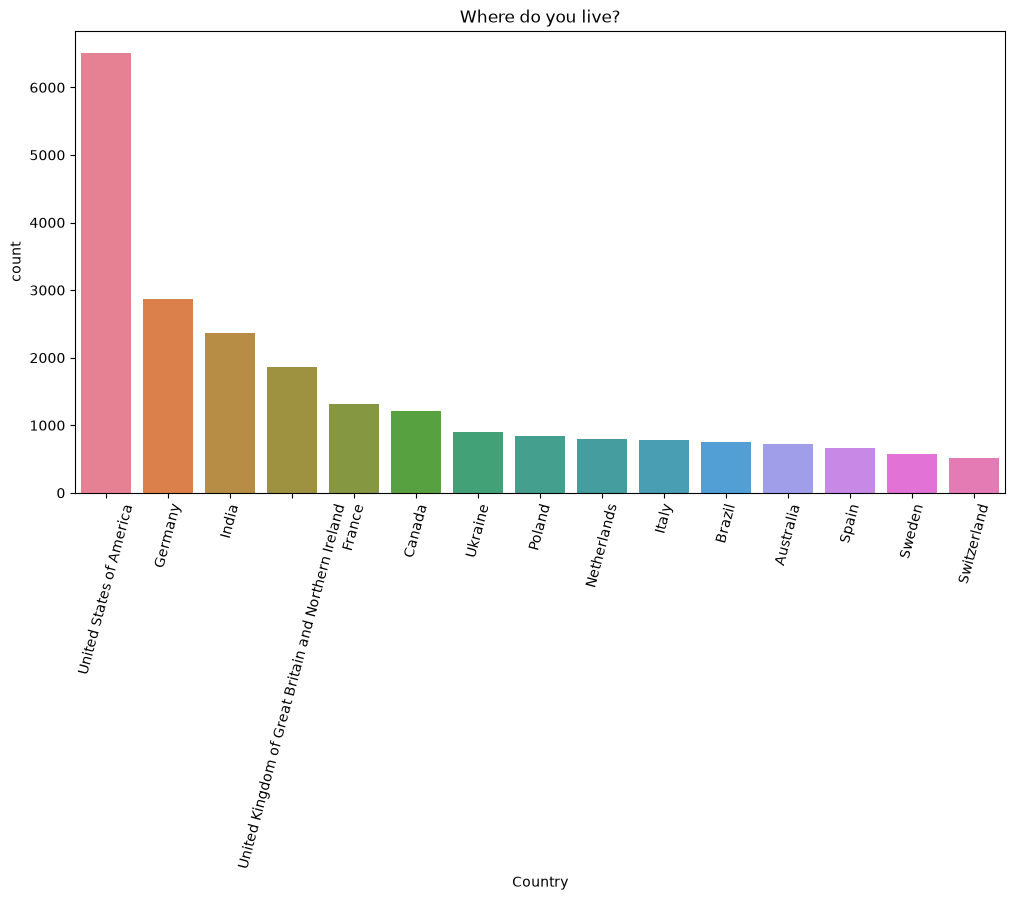

In [85]:
plt.figure(figsize=(12, 6))
plt.xticks(rotation=75)
plt.title(schema_raw.Country)
sns.barplot(x=top_countries.index, y=top_countries, hue=top_countries.index, palette='husl');

## Age

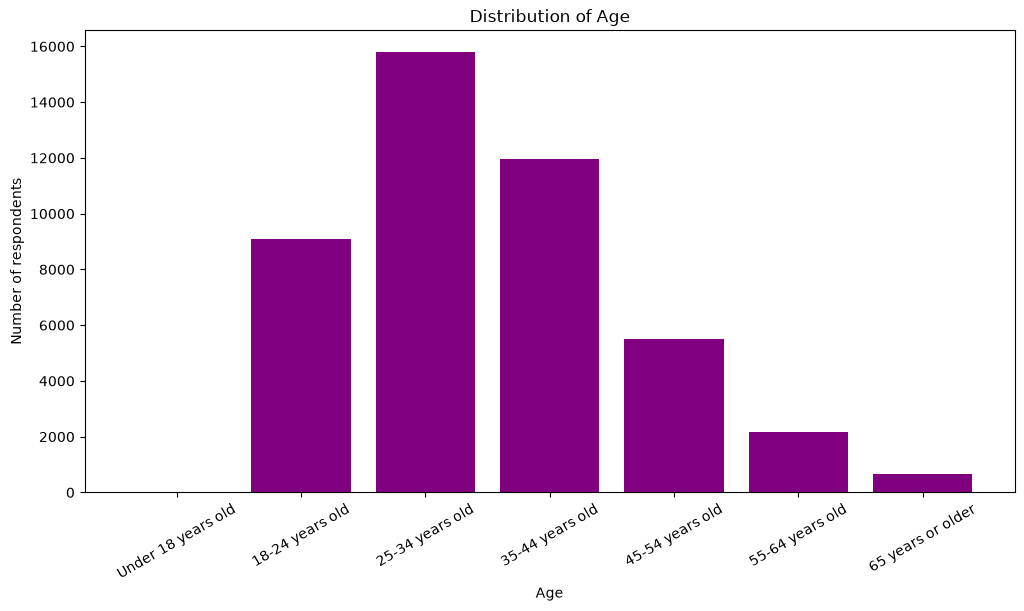

In [109]:
plt.figure(figsize=(12, 6))
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Number of respondents')
age_counts = survey_df.Age.value_counts(sort=False)
plt.bar(age_counts.index.astype(str), age_counts, color='purple')
plt.xticks(rotation=30);

## Main branch (replaces Gender pie chart)

In [87]:
main_branch_counts = survey_df.MainBranch.value_counts()
main_branch_counts

MainBranch
I am a developer by profession                                                                35866
I am not primarily a developer, but I write code sometimes as part of my work/studies          4005
I am learning to code                                                                          2212
I code primarily as a hobby                                                                    1674
I used to be a developer by profession, but no longer am                                       1106
I work with developers or my work supports developers but am not a developer by profession      685
Name: count, dtype: int64

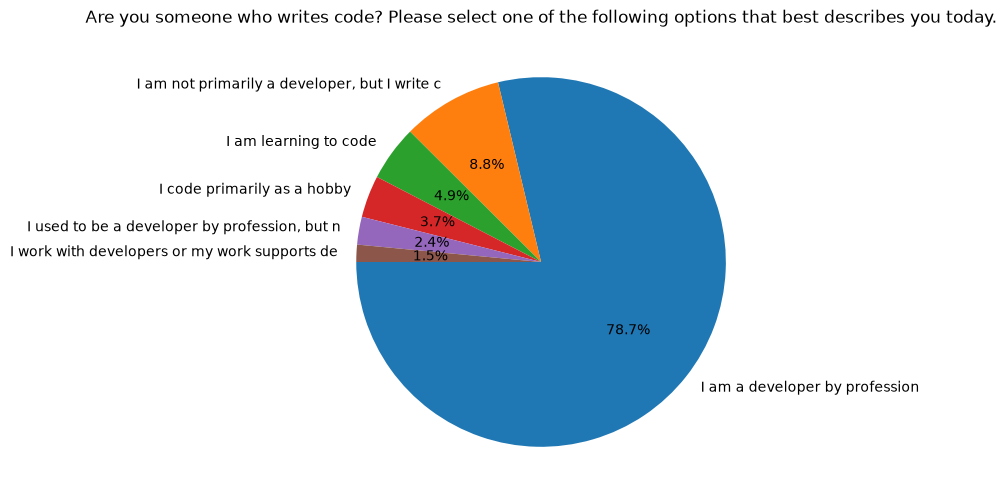

In [88]:
plt.figure(figsize=(12, 6))
plt.pie(main_branch_counts, labels=main_branch_counts.index.str.slice(0, 45), autopct='%1.1f%%', startangle=180);
plt.title(schema_raw.MainBranch);

## Education

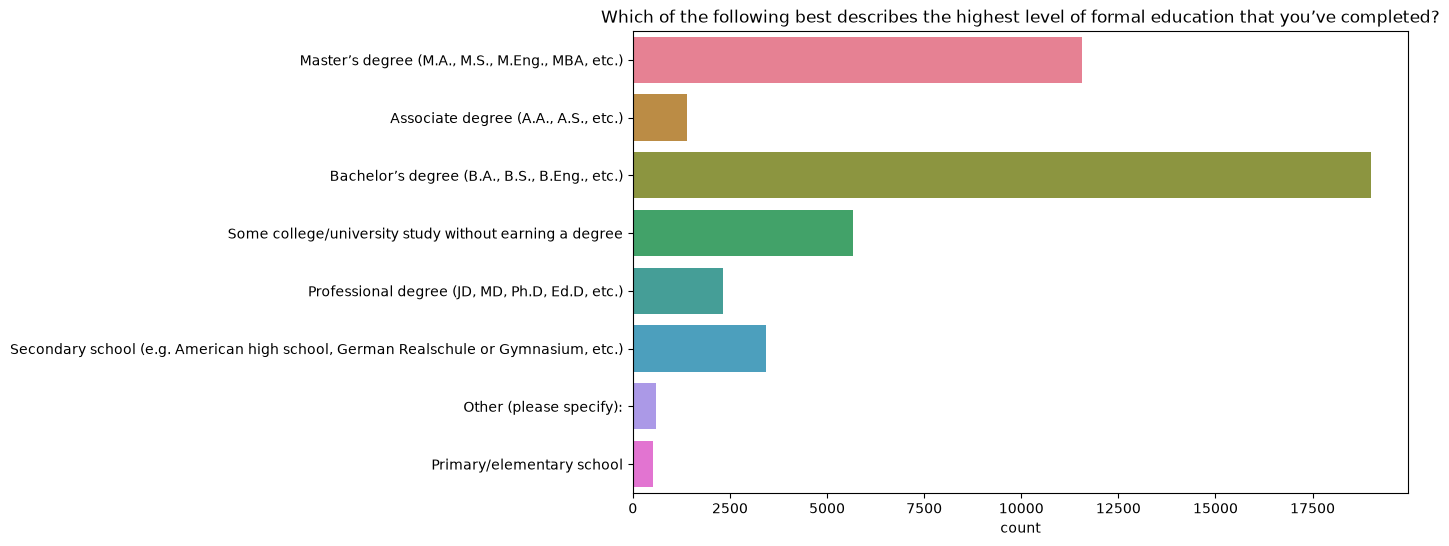

In [89]:
plt.figure(figsize=(10, 6))
sns.countplot(y=survey_df.EdLevel, hue=survey_df.EdLevel, legend=False, palette='husl')
plt.title(schema_raw['EdLevel'])
plt.ylabel(None);

## Industry (replaces UndergradMajor)

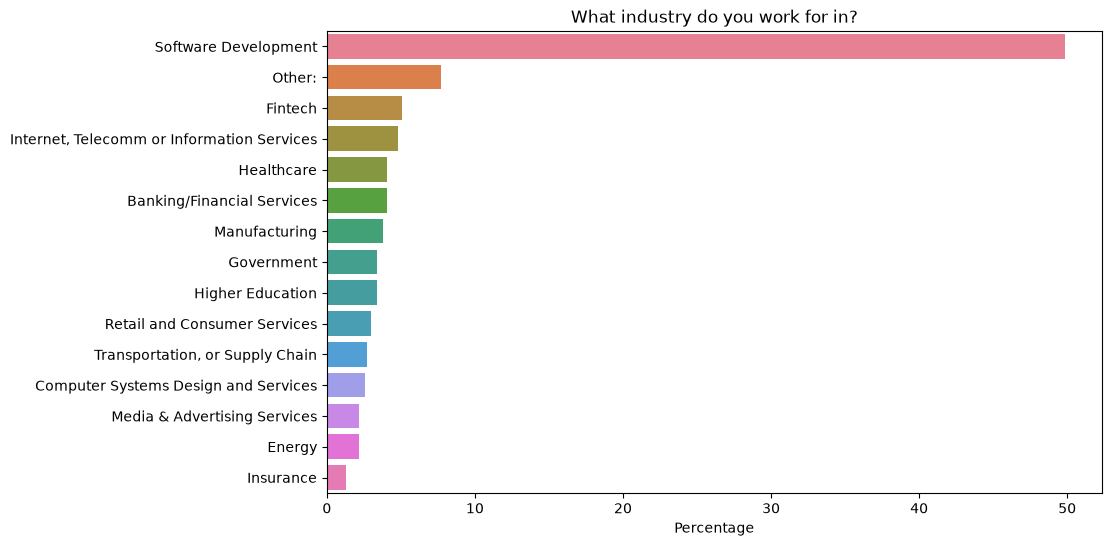

In [90]:
industry_pct = survey_df.Industry.value_counts() * 100 / survey_df.Industry.count()

plt.figure(figsize=(10, 6))
sns.barplot(x=industry_pct, y=industry_pct.index, hue=industry_pct.index, legend=False, palette='husl')
plt.title(schema_raw.Industry)
plt.ylabel(None);
plt.xlabel('Percentage');

## Employment

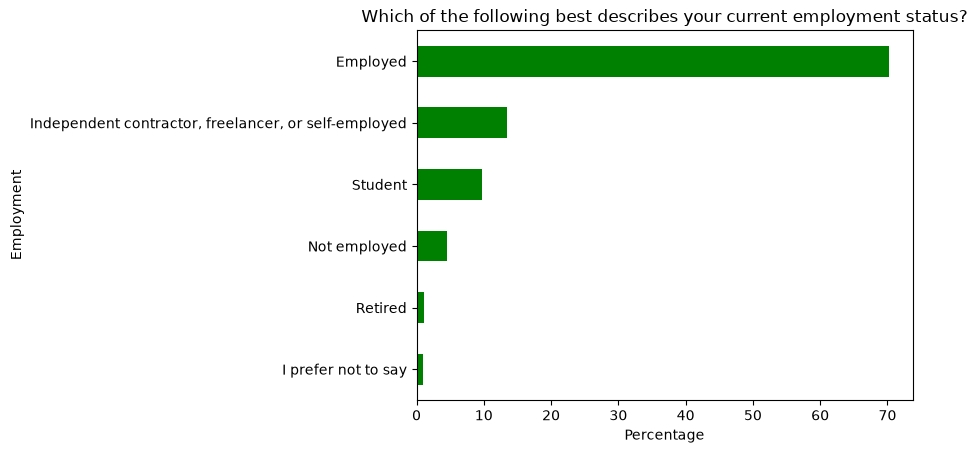

In [91]:
(survey_df.Employment.value_counts(normalize=True, ascending=True)*100).plot(kind='barh', color='g')
plt.title(schema_raw.Employment)
plt.xlabel('Percentage');

## Developer type

In [92]:
schema_raw.DevType

'Which of the following describes your current job or the job you had for the most time in the past year?'

In [93]:
survey_df.DevType.value_counts()

DevType
Developer, full-stack                            11806
Developer, back-end                               6225
Student                                           2883
Architect, software or solutions                  2457
Developer, front-end                              1858
Developer, desktop or enterprise applications     1793
Other (please specify):                           1463
Developer, mobile                                 1321
Developer, embedded applications or devices       1218
Academic researcher                               1017
Engineering manager                                942
DevOps engineer or professional                    902
Data engineer                                      673
AI/ML engineer                                     637
Data scientist                                     499
Senior executive (C-suite, VP, etc.)               456
Developer, game or graphics                        434
Cloud infrastructure engineer                      389
Fo

In [94]:
devType_counts = (
    survey_df["DevType"]
    .dropna()
    .str.split(";")
    .explode()
    .value_counts()
)
devType_counts

DevType
Developer, full-stack                            11806
Developer, back-end                               6225
Student                                           2883
Architect, software or solutions                  2457
Developer, front-end                              1858
Developer, desktop or enterprise applications     1793
Other (please specify):                           1463
Developer, mobile                                 1321
Developer, embedded applications or devices       1218
Academic researcher                               1017
Engineering manager                                942
DevOps engineer or professional                    902
Data engineer                                      673
AI/ML engineer                                     637
Data scientist                                     499
Senior executive (C-suite, VP, etc.)               456
Developer, game or graphics                        434
Cloud infrastructure engineer                      389
Fo

In [95]:
def split_multicolumn(col_series):
    result_df = col_series.to_frame()
    options = []
    # Iterate over the column
    for idx, value  in col_series[col_series.notnull()].items():
        # Break each value into list of options
        for option in value.split(';'):
            # Add the option as a column to result
            if not option in result_df.columns:
                options.append(option)
                result_df[option] = False
            # Mark the value in the option column as True
            result_df.at[idx, option] = True
    return result_df[options]

`DevType` is single-choice in 2025, so `split_multicolumn` is more useful on the multi-choice language column:

In [96]:
language_df = split_multicolumn(survey_df.LanguageHaveWorkedWith)
language_df

,Bash/Shell (all shells),Dart,SQL,Java,HTML/CSS,JavaScript,TypeScript,Kotlin,C,C#,...,Rust,R,Zig,Groovy,F#,GDScript,Erlang,Prolog,Mojo,Gleam
0,True,True,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,True,False,False,True,True,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,True,True,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,True,True,True,True,True,False,True,True,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49186,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
49187,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
49188,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
49189,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


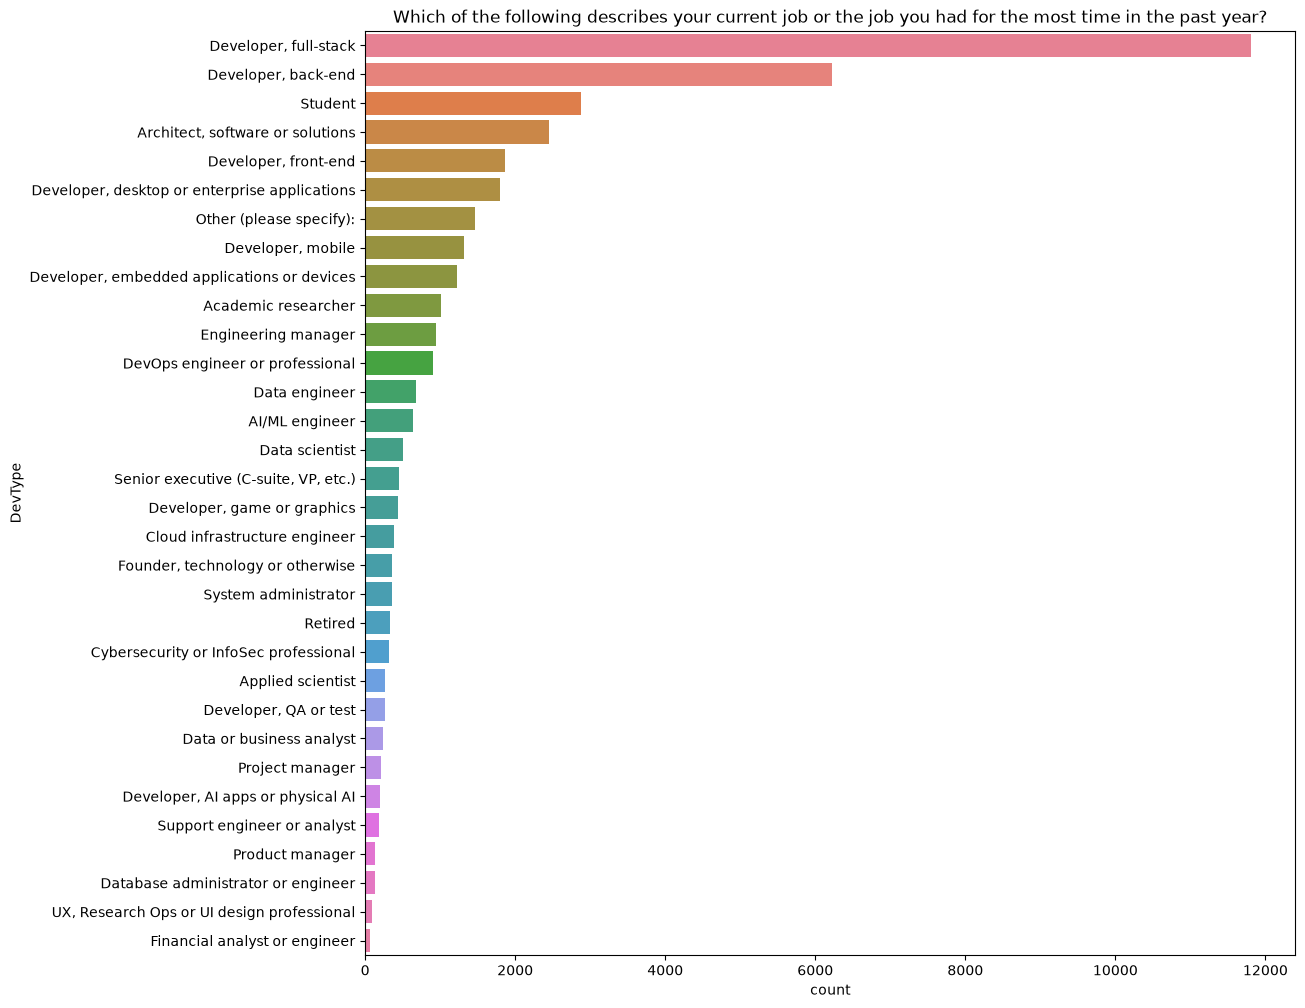

In [97]:
plt.figure(figsize=(12, 12))
sns.barplot(x=devType_counts, y=devType_counts.index, hue=devType_counts.index, palette='husl', legend=False)
plt.title(schema_raw.DevType);
plt.xlabel('count');

## Experience

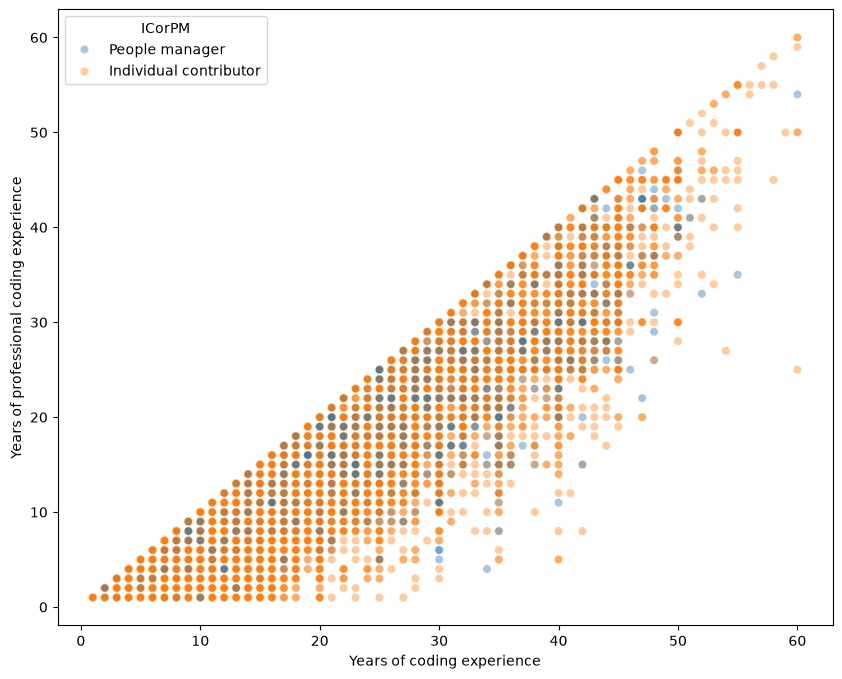

In [98]:
plt.figure(figsize=(10, 8))
sns.scatterplot(x='YearsCode', y='WorkExp', hue='ICorPM', data=survey_df, alpha=0.4)
plt.xlabel("Years of coding experience")
plt.ylabel("Years of professional coding experience");

## New in 2025: AI tools

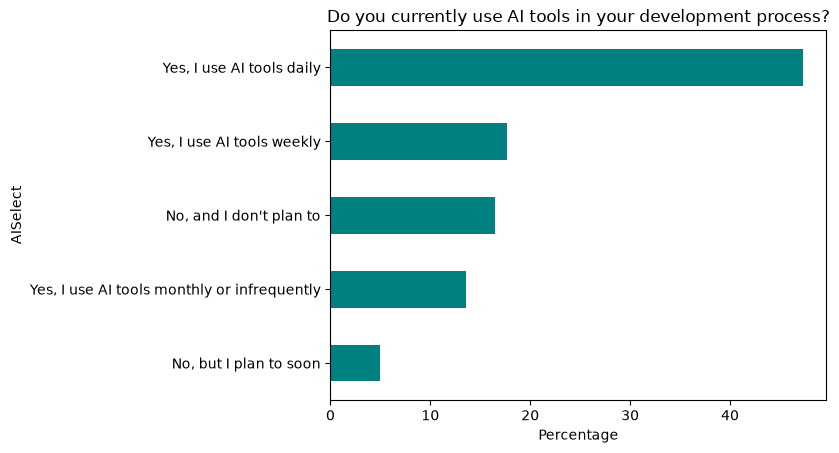

In [99]:
ai_select_pct = survey_df.AISelect.value_counts(normalize=True, ascending=True) * 100
ai_select_pct.plot(kind='barh', color='teal')
plt.title(schema_raw.AISelect)
plt.xlabel('Percentage');

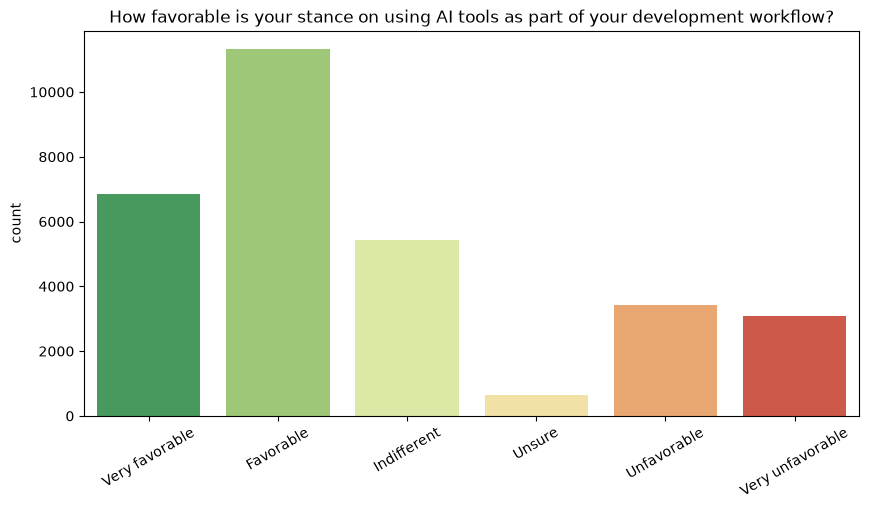

In [100]:
sent_order = ['Very favorable', 'Favorable', 'Indifferent', 'Unsure', 'Unfavorable', 'Very unfavorable']
plt.figure(figsize=(10, 5))
sns.countplot(x=survey_df.AISent, order=sent_order, hue=survey_df.AISent, hue_order=sent_order, palette='RdYlGn_r', legend=False)
plt.title(schema_raw.AISent)
plt.xticks(rotation=30)
plt.xlabel(None);

## New in 2025: work, satisfaction and pay

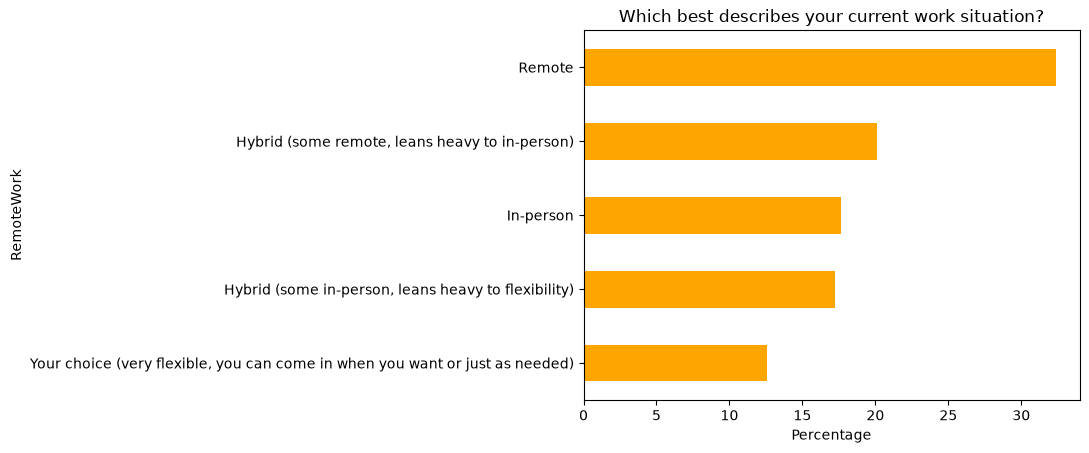

In [101]:
(survey_df.RemoteWork.value_counts(normalize=True, ascending=True) * 100).plot(kind='barh', color='orange')
plt.title(schema_raw.RemoteWork)
plt.xlabel('Percentage');

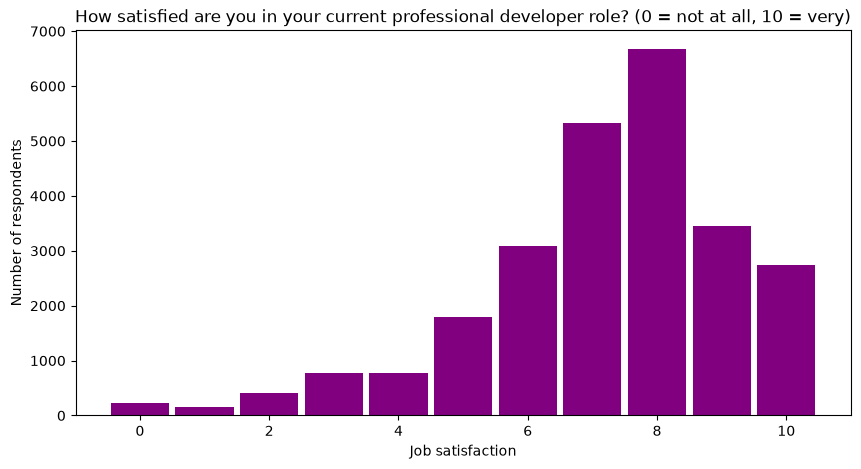

In [102]:
plt.figure(figsize=(10, 5))
plt.title(schema_raw.JobSat + ' (0 = not at all, 10 = very)')
plt.hist(survey_df.JobSat, bins=np.arange(-0.5, 11, 1), color='purple', rwidth=0.9)
plt.xlabel('Job satisfaction')
plt.ylabel('Number of respondents');

In [103]:
median_comp = (
    survey_df[survey_df.Country.isin(top_countries.index)]
    .groupby('Country')['ConvertedCompYearly']
    .median()
    .sort_values(ascending=False)
)
median_comp

Country
United States of America                                150000.0
Switzerland                                             138872.0
Australia                                                97514.0
United Kingdom of Great Britain and Northern Ireland     94618.0
Canada                                                   90468.0
Netherlands                                              81210.0
Germany                                                  81210.0
Sweden                                                   71279.0
Spain                                                    62648.0
France                                                   61488.0
Poland                                                   60278.0
Italy                                                    47566.0
Brazil                                                   27488.0
Ukraine                                                  25000.0
India                                                    16274.0
Name: ConvertedCo

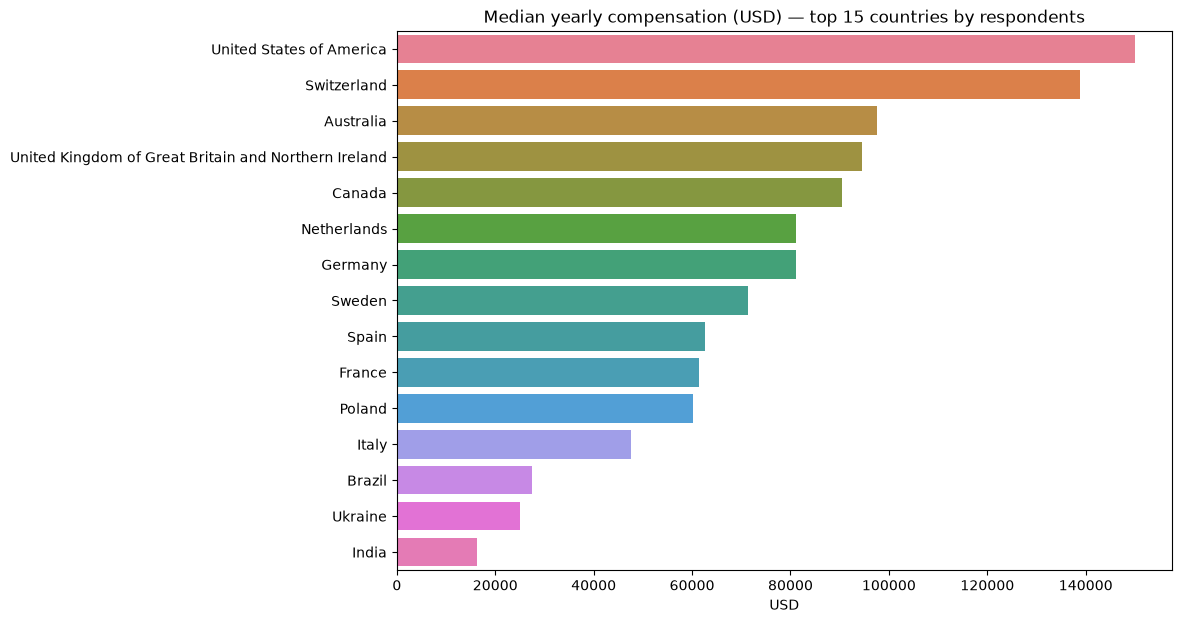

In [104]:
plt.figure(figsize=(10, 7))
sns.barplot(x=median_comp, y=median_comp.index, hue=median_comp.index, palette='husl', legend=False)
plt.title('Median yearly compensation (USD) — top 15 countries by respondents')
plt.xlabel('USD')
plt.ylabel(None);

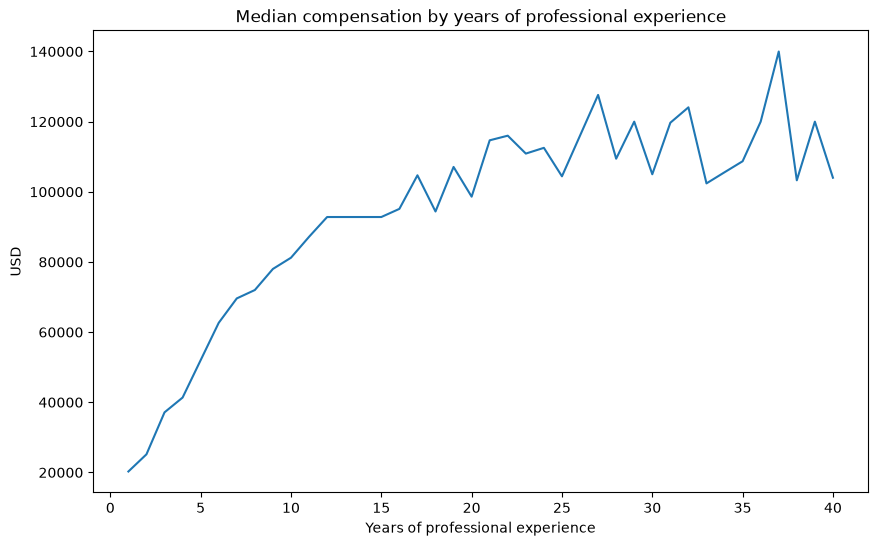

In [105]:
plt.figure(figsize=(10, 6))
sns.lineplot(x='WorkExp', y='ConvertedCompYearly', data=survey_df[survey_df.WorkExp <= 40], estimator='median', errorbar=None)
plt.title('Median compensation by years of professional experience')
plt.xlabel('Years of professional experience')
plt.ylabel('USD');